# Q-Molecule
## Qiskit Fall Fest 2026 — Phase 1: C1 H2 Ground-State Energy

This project uses a precomputed H2 Hamiltonian, a variational quantum eigensolver (VQE), Processor A/B circuit compilation, and an illustrative noise experiment.

All results are from classical simulation and compilation, not physical quantum hardware.

In [16]:
from pathlib import Path
import subprocess
import sys

# Find the Q-Molecule project folder
ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "processors" / "processor_A.py").exists()
    ),
    None,
)

if ROOT is None:
    raise RuntimeError(
        "Cannot find the Q-Molecule project folder. "
        "Open main.ipynb from the project root."
    )

print("Project folder:", ROOT)

steps = [
    ("Generate Processor A configuration",
     ROOT / "processors" / "processor_A.py"),
    ("Generate Processor B configuration",
     ROOT / "processors" / "processor_B.py"),
    ("Run H2 solver and save optimized parameters",
     ROOT / "src" / "h2_solver.py"),
    ("Run Processor A/B compilation benchmark",
     ROOT / "src" / "benchmark_processors.py"),
    ("Run illustrative noise experiment",
     ROOT / "src" / "noise_experiment.py"),
]

for description, script_path in steps:
    print(f"\n{'=' * 60}")
    print(description)
    print("=" * 60)

    subprocess.run(
        [sys.executable, str(script_path)],
        cwd=ROOT,
        check=True,
    )

    print(f"PASS: {description}")

print("\nALL PROJECT STEPS COMPLETED SUCCESSFULLY")
print("Review results/tables and results/figures before submission.")

Project folder: c:\Users\DELL\Desktop\Q-Molecule

Generate Processor A configuration
PASS: Generate Processor A configuration

Generate Processor B configuration
PASS: Generate Processor B configuration

Run H2 solver and save optimized parameters
PASS: Run H2 solver and save optimized parameters

Run Processor A/B compilation benchmark
PASS: Run Processor A/B compilation benchmark

Run illustrative noise experiment
PASS: Run illustrative noise experiment

ALL PROJECT STEPS COMPLETED SUCCESSFULLY
Review results/tables and results/figures before submission.


## 1. H2 Ground-State Energy Results

This section reports the exact reference energy and the variational quantum eigensolver (VQE) result from the stored H2 Hamiltonian.

The exact reference is calculated from the same precomputed Hamiltonian; molecular integrals were not generated locally.

In [17]:
import json
from pathlib import Path
import pandas as pd

ROOT = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "results" / "tables" / "h2_energy.json").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot find results/tables/h2_energy.json")

with (ROOT / "results" / "tables" / "h2_energy.json").open(
    encoding="utf-8"
) as f:
    energy = json.load(f)

energy_table = pd.DataFrame([
    ("Exact electronic energy (Hartree)",
     energy["exact_electronic_energy_hartree"]),
    ("Nuclear repulsion energy (Hartree)",
     energy["nuclear_repulsion_energy_hartree"]),
    ("Exact total energy (Hartree)",
     energy["exact_total_energy_hartree"]),
    ("VQE electronic energy (Hartree)",
     energy["vqe_electronic_energy_hartree"]),
    ("VQE total energy (Hartree)",
     energy["vqe_total_energy_hartree"]),
    ("Absolute total-energy error (Hartree)",
     energy["absolute_total_energy_error_hartree"]),
    ("Optimizer successful",
     energy["optimizer_success"]),
    ("Within stated chemical-accuracy threshold",
     energy["within_chemical_accuracy"]),
], columns=["Metric", "Result"])

def format_energy_row(row):
    metric = row["Metric"]
    value = row["Result"]

    if metric in [
        "Optimizer successful",
        "Within stated chemical-accuracy threshold",
    ]:
        return str(value)

    if metric == "Absolute total-energy error (Hartree)":
        return f"{float(value):.12e}"

    return f"{float(value):.6f}"


energy_table["Result"] = energy_table.apply(
    format_energy_row, axis=1
)

print(energy_table.to_string(index=False))

                                   Metric             Result
        Exact electronic energy (Hartree)          -1.857275
       Nuclear repulsion energy (Hartree)           0.719969
             Exact total energy (Hartree)          -1.137306
          VQE electronic energy (Hartree)          -1.857275
               VQE total energy (Hartree)          -1.137306
    Absolute total-energy error (Hartree) 1.367794766338e-11
                     Optimizer successful               True
Within stated chemical-accuracy threshold               True


## 2. Processor A vs Processor B

This section compares the compilation of the same four-qubit H2 ansatz on the two participant-designed processor connectivity graphs.

Metrics include physical qubits, compiled circuit depth, CX gate count, routing SWAP overhead, and compilation time. These measurements are from classical compilation, not physical hardware.

In [18]:
import pandas as pd
from pathlib import Path

ROOT = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "results" / "tables" / "processor_comparison.csv").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot find processor_comparison.csv")

benchmark = pd.read_csv(
    ROOT / "results" / "tables" / "processor_comparison.csv"
)

h2_comparison = benchmark[
    benchmark["benchmark_type"] == "C1_H2_ansatz"
][[
    "processor",
    "physical_qubits_available",
    "logical_qubits",
    "final_transpiled_depth",
    "final_transpiled_cx_count",
    "cx_overhead_vs_unconstrained",
    "routing_swaps_before_decomposition",
    "compile_time_seconds",
]].copy()

h2_comparison.columns = [
    "Processor",
    "Physical qubits",
    "Logical qubits",
    "Final circuit depth",
    "Final CX gates",
    "CX overhead",
    "Routing SWAPs",
    "Compile time (s)",
]

h2_comparison["Compile time (s)"] = h2_comparison[
    "Compile time (s)"
].map(lambda value: f"{value:.6f}")

print(h2_comparison.to_string(index=False))

  Processor  Physical qubits  Logical qubits  Final circuit depth  Final CX gates  CX overhead  Routing SWAPs Compile time (s)
Processor A                5               4                   15               4            0              0         0.004891
Processor B                9               4                   23              10            6              2         0.005049


## 3. Processor Connectivity and Benchmark Graphs

These figures show the participant-designed processor connectivity graphs and the measured compilation comparison. All results are from classical simulation and compilation.

processor_A_graph.png


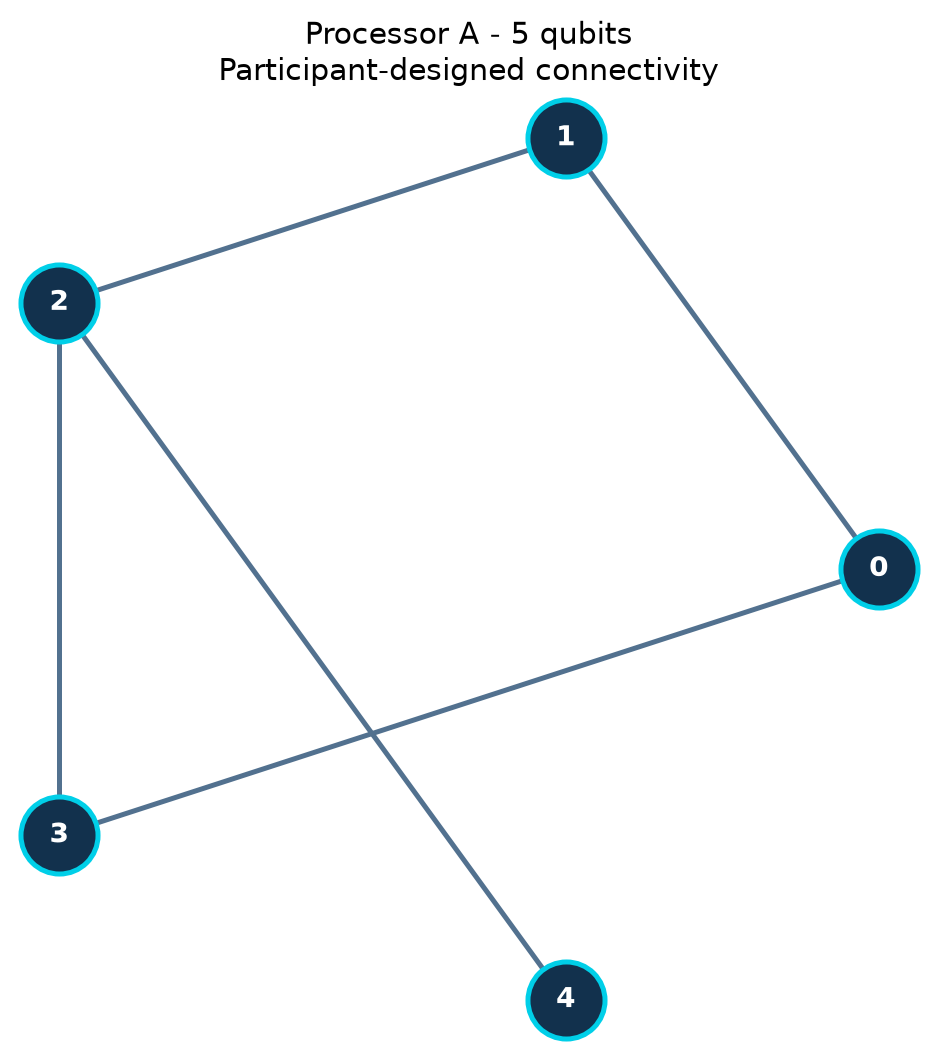

processor_B_graph.png


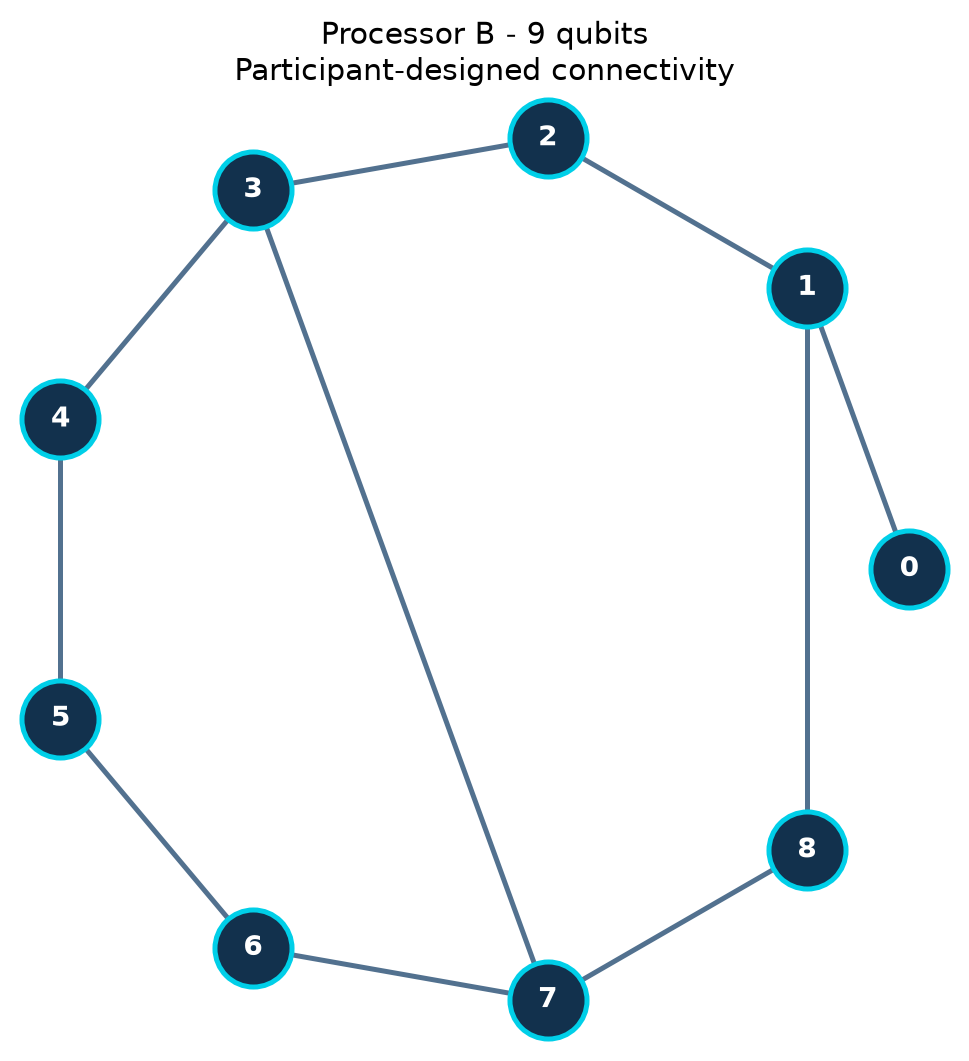

processor_comparison.png


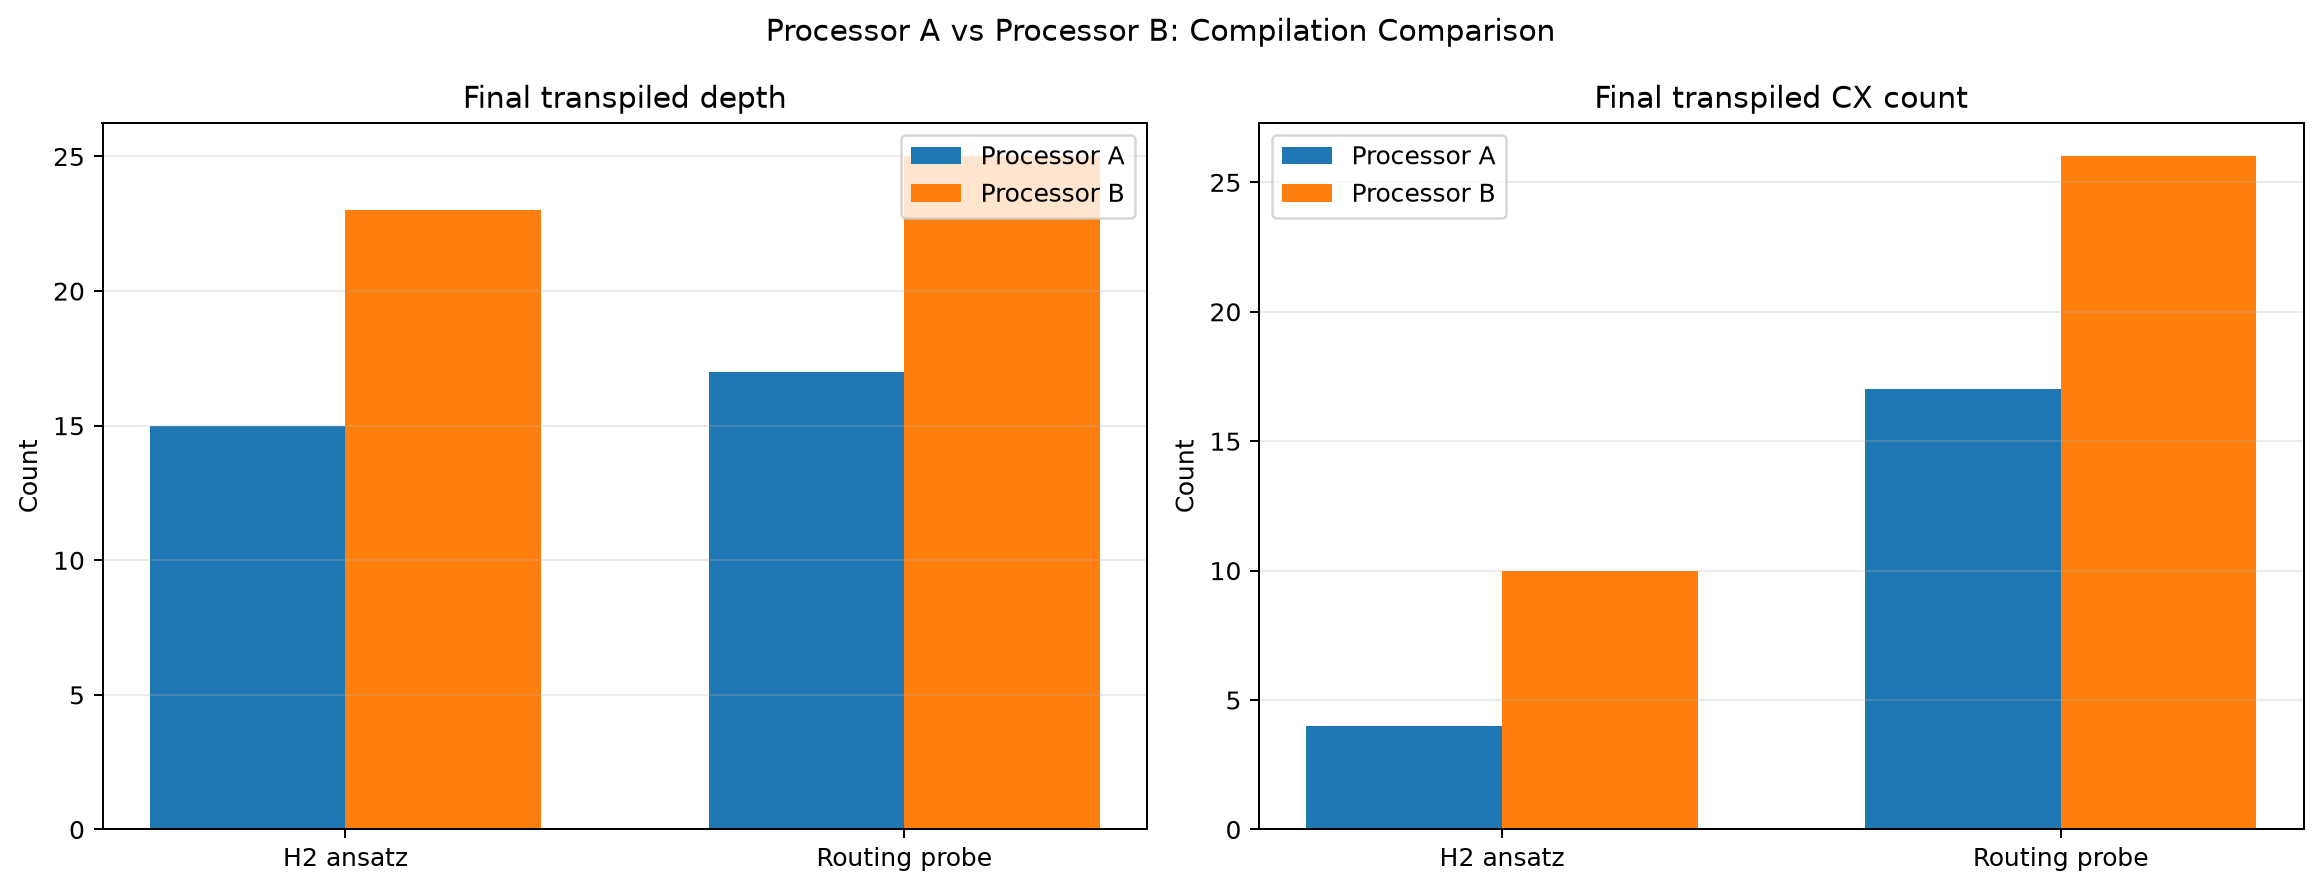

In [19]:
from IPython.display import display, Image
from pathlib import Path

ROOT = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "results" / "figures" / "processor_A_graph.png").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot find results/figures")

for filename in [
    "processor_A_graph.png",
    "processor_B_graph.png",
    "processor_comparison.png",
]:
    image_path = ROOT / "results" / "figures" / filename
    print(filename)
    display(Image(filename=str(image_path)))

## 4. Noise Sensitivity Experiment

This experiment compares H2 energy estimates using a common illustrative noise model across three simulator runs per processor.

The noise probabilities are assumptions, not official hardware specifications. All results are from simulation, not physical quantum hardware.

  Processor  Runs  Shots per Pauli term  Mean total energy (Ha)  Sample standard deviation (Ha)  Mean absolute error (Ha)
Processor A     3                  8192               -1.045838                        0.002398                  0.091468
Processor B     3                  8192               -1.016180                        0.002278                  0.121126


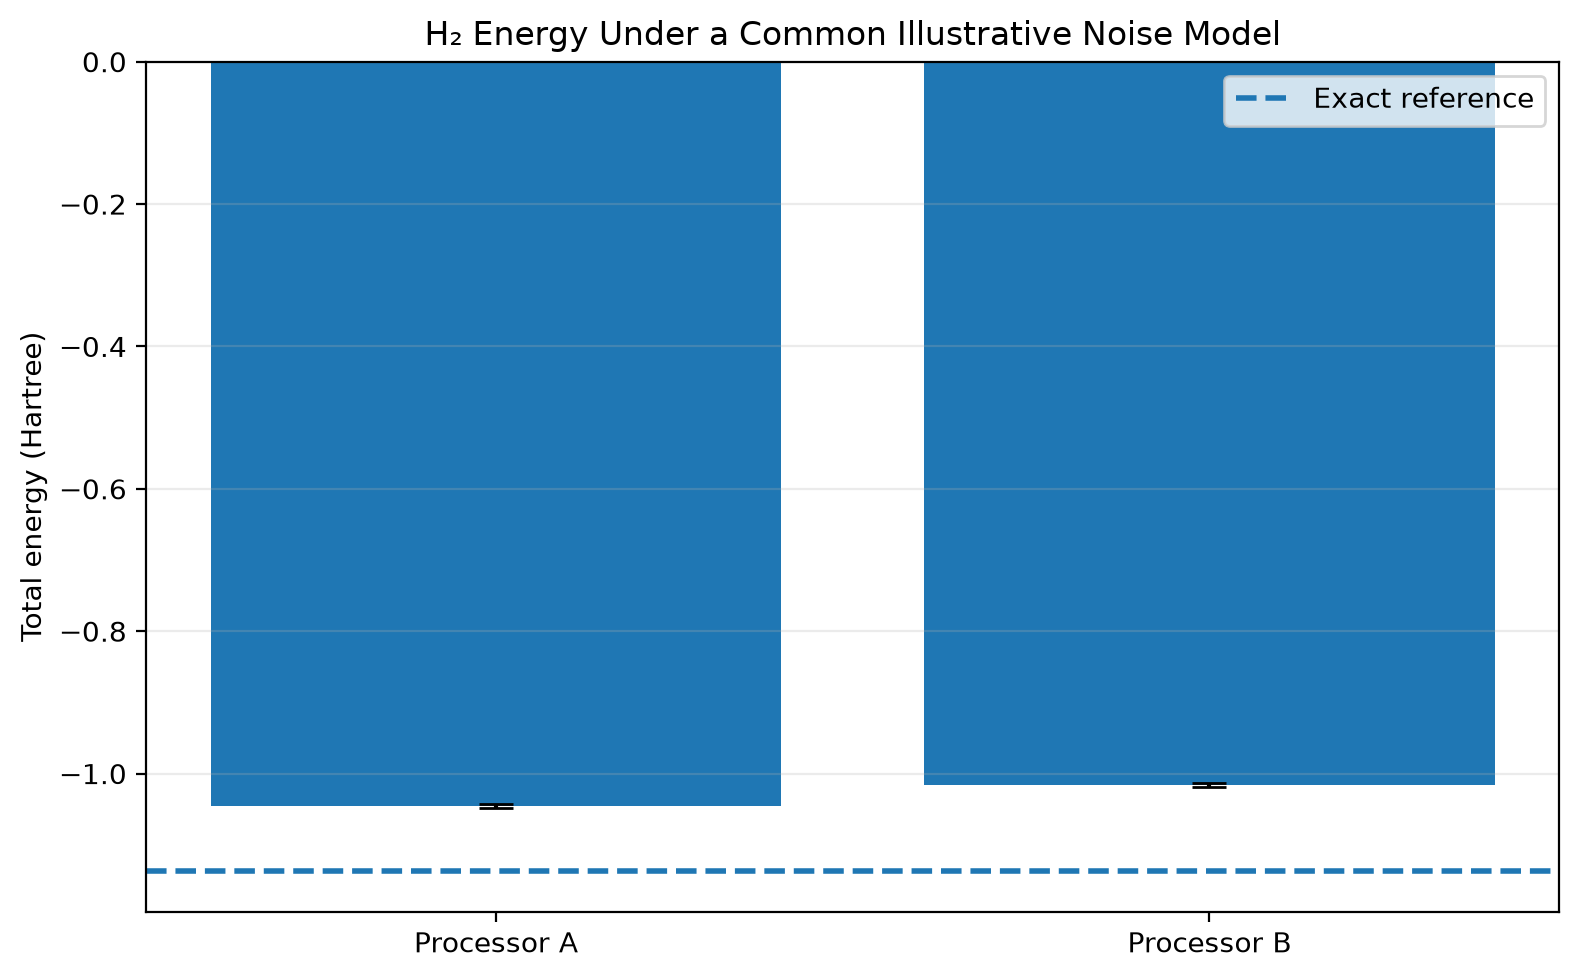

In [20]:
import json
import pandas as pd
from pathlib import Path
from IPython.display import display, Image

ROOT = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "results" / "tables" / "noise_sensitivity.json").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot find noise_sensitivity.json")

with (ROOT / "results" / "tables" / "noise_sensitivity.json").open(
    encoding="utf-8"
) as f:
    noise_data = json.load(f)

noise_table = pd.DataFrame(noise_data["results"])[[
    "processor",
    "repeat_count",
    "shots_per_pauli_term",
    "mean_total_energy_hartree",
    "sample_std_total_energy_hartree",
    "mean_absolute_error_from_exact_hartree",
]]

noise_table.columns = [
    "Processor",
    "Runs",
    "Shots per Pauli term",
    "Mean total energy (Ha)",
    "Sample standard deviation (Ha)",
    "Mean absolute error (Ha)",
]

print(noise_table.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

noise_figure = ROOT / "results" / "figures" / "noise_sensitivity.png"

if not noise_figure.exists():
    raise FileNotFoundError(f"Missing noise graph: {noise_figure}")

display(Image(filename=str(noise_figure)))

## 5. Scientific Limitations and Reproducibility

- The H2 Hamiltonian uses precomputed coefficients rounded to eight decimal places. Molecular integrals were not generated locally.
- The exact reference energy was calculated from the same stored Hamiltonian.
- The variational ansatz is hardware-efficient, not UCCSD.
- Processor A and Processor B use participant-designed connectivity graphs and port assignments, not verified official hardware configurations.
- Noise probabilities are illustrative assumptions, not official processor specifications.
- All results come from classical simulation and compilation. No physical quantum hardware was accessed.
- Noise statistics use three simulator runs per processor, so the estimated run-to-run variability is limited.

### Reproducing the Results

Use Python 3.12 and install dependencies with `python -m pip install -r requirements.txt`.

Run the processor configuration scripts, H2 solver, compilation benchmark, and noise experiment from the project root. The generated tables and figures are saved in `results/tables/` and `results/figures/`.

### AI Assistance Disclosure

AI assistance was used to help draft, debug, and document portions of this project. The project author is responsible for reviewing the implementation, results, assumptions, and final submission.